![No CAP Project](nocap.png)

_Authored by La’ Neyshia Drew, Lucas Carreira, Matthew Konar, Sarah Baeza, and Sierra Mullins_

# Phase Two: Exploratory Data Analysis & Baseline Modeling

# Load Data

Load data in CSV format from HCDR datatset to a folder called "data"

In [1]:
import os
import pandas as pd
import numpy as np

DATA_DIR = "/root/shared/group1-hcdr-no-cap/data"  # container path, see README

# Check that Python can find the folder
print(os.listdir(DATA_DIR))

['.gitkeep', 'application_test.csv', 'application_train.csv', 'bureau.csv', 'bureau_balance.csv', 'credit_card_balance.csv', 'HomeCredit_columns_description.csv', 'installments_payments.csv', 'POS_CASH_balance.csv', 'previous_application.csv', 'sample_submission.csv', 'submission_phase2.csv']


In [2]:
# Find all CSV files
csv_files = [f for f in os.listdir(DATA_DIR) if f.endswith(".csv")]

# Report each file's shape. The tables total several GB in memory and the container has about
# 7.6 GB of RAM, so they are not kept: only the first column is read to count rows. The EDA
# section below reads the history tables again, one at a time.
for file in csv_files:
    name = file.replace(".csv", "")
    path = os.path.join(DATA_DIR, file)
    n_rows = len(pd.read_csv(path, usecols=[0], encoding="latin1"))
    n_cols = pd.read_csv(path, nrows=0, encoding="latin1").shape[1]
    print(f"{name}: ({n_rows}, {n_cols})")

application_test: (48744, 121)
application_train: (307511, 122)
bureau: (1716428, 17)
bureau_balance: (27299925, 3)
credit_card_balance: (3840312, 23)
HomeCredit_columns_description: (219, 5)
installments_payments: (13605401, 8)
POS_CASH_balance: (10001358, 8)
previous_application: (1670214, 37)
sample_submission: (48744, 2)
submission_phase2: (48744, 2)


Column Descriptions

In [3]:
# Load Home Credit column descriptions
column_descriptions = pd.read_csv(
    os.path.join(DATA_DIR, "HomeCredit_columns_description.csv"),
    encoding="latin1"
)

# Display the entire table
pd.set_option("display.max_rows", None)
pd.set_option("display.max_columns", None)
pd.set_option("display.max_colwidth", None)

display(column_descriptions)

,Unnamed: 0,Table,Row,Description,Special
0,1,application_{train|test}.csv,SK_ID_CURR,ID of loan in our sample,NaN
1,2,application_{train|test}.csv,TARGET,"Target variable (1 - client with payment difficulties: he/she had late payment more than X days on at least one of the first Y installments of the loan in our sample, 0 - all other cases)",NaN
2,5,application_{train|test}.csv,NAME_CONTRACT_TYPE,Identification if loan is cash or revolving,NaN
3,6,application_{train|test}.csv,CODE_GENDER,Gender of the client,NaN
4,7,application_{train|test}.csv,FLAG_OWN_CAR,Flag if the client owns a car,NaN
5,8,application_{train|test}.csv,FLAG_OWN_REALTY,Flag if client owns a house or flat,NaN
6,9,application_{train|test}.csv,CNT_CHILDREN,Number of children the client has,NaN
7,10,application_{train|test}.csv,AMT_INCOME_TOTAL,Income of the client,NaN
8,11,application_{train|test}.csv,AMT_CREDIT,Credit amount of the loan,NaN
9,12,application_{train|test}.csv,AMT_ANNUITY,Loan annuity,NaN


## Dataset Descriptions

* __application_train/application_test:__ the main training and testing data with information about each loan application at Home Credit. Every loan has its own row and is identified by the feature SK_ID_CURR. The training application data comes with the TARGET indicating __0: the loan was repaid__ or __1: the loan was not repaid__. The target variable defines if the client had payment difficulties meaning he/she had late payment more than X days on at least one of the first Y installments of the loan. Such case is marked as 1 while other all other cases as 0.
* __bureau:__ data concerning client's previous credits from other financial institutions. Each previous credit has its own row in bureau, but one loan in the application data can have multiple previous credits.
* __bureau_balance:__ monthly data about the previous credits in bureau. Each row is one month of a previous credit, and a single previous credit can have multiple rows, one for each month of the credit length.
* __previous_application:__ previous applications for loans at Home Credit of clients who have loans in the application data. Each current loan in the application data can have multiple previous loans. Each previous application has one row and is identified by the feature SK_ID_PREV.
* __POS_CASH_BALANCE:__ monthly data about previous point of sale or cash loans clients have had with Home Credit. Each row is one month of a previous point of sale or cash loan, and a single previous loan can have many rows.
* credit_card_balance: monthly data about previous credit cards clients have had with Home Credit. Each row is one month of a credit card balance, and a single credit card can have many rows.
* __installments_payment:__ payment history for previous loans at Home Credit. There is one row for every made payment and one row for every missed payment.

# Exploratory Data Analysis

## Data Summary - Size, Variables and Target

In [4]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Load training data
application_train = pd.read_csv(
    os.path.join(DATA_DIR, "application_train.csv")
)

# Basic overview
print("Dataset shape:", application_train.shape)
display(application_train.head())

# Data types and non-null counts
application_train.info()

# Summary statistics (top ten features)
display(application_train.describe().T.head(10))

Dataset shape: (307511, 122)


,SK_ID_CURR,TARGET,NAME_CONTRACT_TYPE,CODE_GENDER,FLAG_OWN_CAR,FLAG_OWN_REALTY,CNT_CHILDREN,AMT_INCOME_TOTAL,AMT_CREDIT,AMT_ANNUITY,AMT_GOODS_PRICE,NAME_TYPE_SUITE,NAME_INCOME_TYPE,NAME_EDUCATION_TYPE,NAME_FAMILY_STATUS,NAME_HOUSING_TYPE,REGION_POPULATION_RELATIVE,DAYS_BIRTH,DAYS_EMPLOYED,DAYS_REGISTRATION,DAYS_ID_PUBLISH,OWN_CAR_AGE,FLAG_MOBIL,FLAG_EMP_PHONE,FLAG_WORK_PHONE,FLAG_CONT_MOBILE,FLAG_PHONE,FLAG_EMAIL,OCCUPATION_TYPE,CNT_FAM_MEMBERS,REGION_RATING_CLIENT,REGION_RATING_CLIENT_W_CITY,WEEKDAY_APPR_PROCESS_START,HOUR_APPR_PROCESS_START,REG_REGION_NOT_LIVE_REGION,REG_REGION_NOT_WORK_REGION,LIVE_REGION_NOT_WORK_REGION,REG_CITY_NOT_LIVE_CITY,REG_CITY_NOT_WORK_CITY,LIVE_CITY_NOT_WORK_CITY,ORGANIZATION_TYPE,EXT_SOURCE_1,EXT_SOURCE_2,EXT_SOURCE_3,APARTMENTS_AVG,BASEMENTAREA_AVG,YEARS_BEGINEXPLUATATION_AVG,YEARS_BUILD_AVG,COMMONAREA_AVG,ELEVATORS_AVG,ENTRANCES_AVG,FLOORSMAX_AVG,FLOORSMIN_AVG,LANDAREA_AVG,LIVINGAPARTMENTS_AVG,LIVINGAREA_AVG,NONLIVINGAPARTMENTS_AVG,NONLIVINGAREA_AVG,APARTMENTS_MODE,BASEMENTAREA_MODE,YEARS_BEGINEXPLUATATION_MODE,YEARS_BUILD_MODE,COMMONAREA_MODE,ELEVATORS_MODE,ENTRANCES_MODE,FLOORSMAX_MODE,FLOORSMIN_MODE,LANDAREA_MODE,LIVINGAPARTMENTS_MODE,LIVINGAREA_MODE,NONLIVINGAPARTMENTS_MODE,NONLIVINGAREA_MODE,APARTMENTS_MEDI,BASEMENTAREA_MEDI,YEARS_BEGINEXPLUATATION_MEDI,YEARS_BUILD_MEDI,COMMONAREA_MEDI,ELEVATORS_MEDI,ENTRANCES_MEDI,FLOORSMAX_MEDI,FLOORSMIN_MEDI,LANDAREA_MEDI,LIVINGAPARTMENTS_MEDI,LIVINGAREA_MEDI,NONLIVINGAPARTMENTS_MEDI,NONLIVINGAREA_MEDI,FONDKAPREMONT_MODE,HOUSETYPE_MODE,TOTALAREA_MODE,WALLSMATERIAL_MODE,EMERGENCYSTATE_MODE,OBS_30_CNT_SOCIAL_CIRCLE,DEF_30_CNT_SOCIAL_CIRCLE,OBS_60_CNT_SOCIAL_CIRCLE,DEF_60_CNT_SOCIAL_CIRCLE,DAYS_LAST_PHONE_CHANGE,FLAG_DOCUMENT_2,FLAG_DOCUMENT_3,FLAG_DOCUMENT_4,FLAG_DOCUMENT_5,FLAG_DOCUMENT_6,FLAG_DOCUMENT_7,FLAG_DOCUMENT_8,FLAG_DOCUMENT_9,FLAG_DOCUMENT_10,FLAG_DOCUMENT_11,FLAG_DOCUMENT_12,FLAG_DOCUMENT_13,FLAG_DOCUMENT_14,FLAG_DOCUMENT_15,FLAG_DOCUMENT_16,FLAG_DOCUMENT_17,FLAG_DOCUMENT_18,FLAG_DOCUMENT_19,FLAG_DOCUMENT_20,FLAG_DOCUMENT_21,AMT_REQ_CREDIT_BUREAU_HOUR,AMT_REQ_CREDIT_BUREAU_DAY,AMT_REQ_CREDIT_BUREAU_WEEK,AMT_REQ_CREDIT_BUREAU_MON,AMT_REQ_CREDIT_BUREAU_QRT,AMT_REQ_CREDIT_BUREAU_YEAR
0,100002,1,Cash loans,M,N,Y,0,202500.0,406597.5,24700.5,351000.0,Unaccompanied,Working,Secondary / secondary special,Single / not married,House / apartment,0.018801,-9461,-637,-3648.0,-2120,NaN,1,1,0,1,1,0,Laborers,1.0,2,2,WEDNESDAY,10,0,0,0,0,0,0,Business Entity Type 3,0.083037,0.262949,0.139376,0.0247,0.0369,0.9722,0.6192,0.0143,0.00,0.0690,0.0833,0.1250,0.0369,0.0202,0.0190,0.0000,0.0000,0.0252,0.0383,0.9722,0.6341,0.0144,0.0000,0.0690,0.0833,0.1250,0.0377,0.022,0.0198,0.0,0.0,0.0250,0.0369,0.9722,0.6243,0.0144,0.00,0.0690,0.0833,0.1250,0.0375,0.0205,0.0193,0.0000,0.00,reg oper account,block of flats,0.0149,"Stone, brick",No,2.0,2.0,2.0,2.0,-1134.0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0.0,0.0,0.0,0.0,0.0,1.0
1,100003,0,Cash loans,F,N,N,0,270000.0,1293502.5,35698.5,1129500.0,Family,State servant,Higher education,Married,House / apartment,0.003541,-16765,-1188,-1186.0,-291,NaN,1,1,0,1,1,0,Core staff,2.0,1,1,MONDAY,11,0,0,0,0,0,0,School,0.311267,0.622246,NaN,0.0959,0.0529,0.9851,0.7960,0.0605,0.08,0.0345,0.2917,0.3333,0.0130,0.0773,0.0549,0.0039,0.0098,0.0924,0.0538,0.9851,0.8040,0.0497,0.0806,0.0345,0.2917,0.3333,0.0128,0.079,0.0554,0.0,0.0,0.0968,0.0529,0.9851,0.7987,0.0608,0.08,0.0345,0.2917,0.3333,0.0132,0.0787,0.0558,0.0039,0.01,reg oper account,block of flats,0.0714,Block,No,1.0,0.0,1.0,0.0,-828.0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0.0,0.0,0.0,0.0,0.0,0.0
2,100004,0,Revolving loans,M,Y,Y,0,67500.0,135000.0,6750.0,135000.0,Unaccompanied,Working,Secondary / secondary special,Single / not married,House / apartment,0.010032,-19046,-225,-4260.0,-2531,26.0,1,1,1,1,1,0,Laborers,1.0,2,2,MONDAY,9,0,0,0,0,0,0,Government,NaN,0.555912,0.729567,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 307511 entries, 0 to 307510
Columns: 122 entries, SK_ID_CURR to AMT_REQ_CREDIT_BUREAU_YEAR
dtypes: float64(65), int64(41), object(16)
memory usage: 286.2+ MB


,count,mean,std,min,25%,50%,75%,max
SK_ID_CURR,307511.0,278180.518577,102790.175348,100002.00000,189145.500000,278202.00000,367142.500000,4.562550e+05
TARGET,307511.0,0.080729,0.272419,0.00000,0.000000,0.00000,0.000000,1.000000e+00
CNT_CHILDREN,307511.0,0.417052,0.722121,0.00000,0.000000,0.00000,1.000000,1.900000e+01
AMT_INCOME_TOTAL,307511.0,168797.919297,237123.146279,25650.00000,112500.000000,147150.00000,202500.000000,1.170000e+08
AMT_CREDIT,307511.0,599025.999706,402490.776996,45000.00000,270000.000000,513531.00000,808650.000000,4.050000e+06
AMT_ANNUITY,307499.0,27108.573909,14493.737315,1615.50000,16524.000000,24903.00000,34596.000000,2.580255e+05
AMT_GOODS_PRICE,307233.0,538396.207429,369446.460540,40500.00000,238500.000000,450000.00000,679500.000000,4.050000e+06
REGION_POPULATION_RELATIVE,307511.0,0.020868,0.013831,0.00029,0.010006,0.01885,0.028663,7.250800e-02
DAYS_BIRTH,307511.0,-16036.995067,4363.988632,-25229.00000,-19682.000000,-15750.00000,-12413.000000,-7.489000e+03
DAYS_EMPLOYED,307511.0,63815.045904,141275.766519,-17912.00000,-2760.000000,-1213.00000,-289.000000,3.652430e+05


There are 307,511 applicants and 122 columns, including the target variable and ID number. 

## Analyze Target

0 = applicant did not experience payment difficulties. 

1 = applicant experienced payment difficulties.

0    282686
1     24825
Name: TARGET, dtype: int64
0    91.927118
1     8.072882
Name: TARGET, dtype: float64


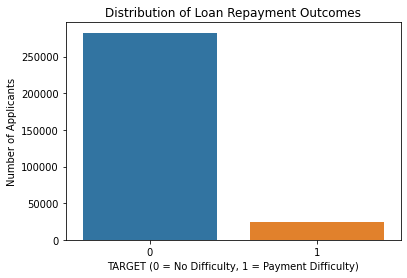

In [5]:
# Target counts
print(application_train["TARGET"].value_counts())

# Target percentages
print(application_train["TARGET"].value_counts(normalize=True) * 100)

# Visualize target distribution
sns.countplot(data=application_train, x="TARGET")
plt.title("Distribution of Loan Repayment Outcomes")
plt.xlabel("TARGET (0 = No Difficulty, 1 = Payment Difficulty)")
plt.ylabel("Number of Applicants")
plt.show()

About 8% of the sample experiences payment dificulty.

## Missing Values and Duplicate Rows

In [6]:
# Calculate missing values
missing = pd.DataFrame({
    "Missing Count": application_train.isnull().sum(),
    "Missing Percentage": application_train.isnull().mean() * 100
})

# Keep columns with missing values
missing = missing[missing["Missing Count"] > 0]

# Sort by missing percentage
missing = missing.sort_values(
    by="Missing Percentage",
    ascending=False
)

display(missing.head(30))

,Missing Count,Missing Percentage
COMMONAREA_MEDI,214865,69.872297
COMMONAREA_AVG,214865,69.872297
COMMONAREA_MODE,214865,69.872297
NONLIVINGAPARTMENTS_MEDI,213514,69.432963
NONLIVINGAPARTMENTS_MODE,213514,69.432963
NONLIVINGAPARTMENTS_AVG,213514,69.432963
FONDKAPREMONT_MODE,210295,68.386172
LIVINGAPARTMENTS_MODE,210199,68.354953
LIVINGAPARTMENTS_MEDI,210199,68.354953
LIVINGAPARTMENTS_AVG,210199,68.354953


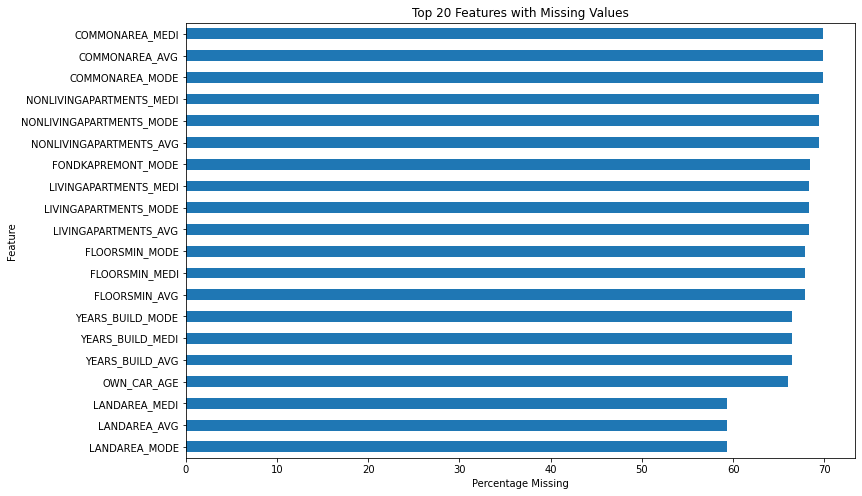

In [7]:
plt.figure(figsize=(12, 8))

missing.head(20)["Missing Percentage"].sort_values().plot(
    kind="barh"
)

plt.title("Top 20 Features with Missing Values")
plt.xlabel("Percentage Missing")
plt.ylabel("Feature")
plt.show()

In [8]:
# Check duplicate applicant IDs
print("Duplicate applicant IDs:",
      application_train["SK_ID_CURR"].duplicated().sum())

# Check duplicate rows
print("Duplicate rows:",
      application_train.duplicated().sum())

# Check unusual employment values
print(application_train["DAYS_EMPLOYED"].value_counts().head())

# Check unique values in binary columns
binary_features = [
    "FLAG_OWN_CAR",
    "FLAG_OWN_REALTY",
    "CODE_GENDER"
]

for col in binary_features:
    print(f"\n{col}:")
    print(application_train[col].value_counts(dropna=False))

Duplicate applicant IDs: 0
Duplicate rows: 0
 365243    55374
-200         156
-224         152
-230         151
-199         151
Name: DAYS_EMPLOYED, dtype: int64

FLAG_OWN_CAR:
N    202924
Y    104587
Name: FLAG_OWN_CAR, dtype: int64

FLAG_OWN_REALTY:
Y    213312
N     94199
Name: FLAG_OWN_REALTY, dtype: int64

CODE_GENDER:
F      202448
M      105059
XNA         4
Name: CODE_GENDER, dtype: int64


## Visualize Variables

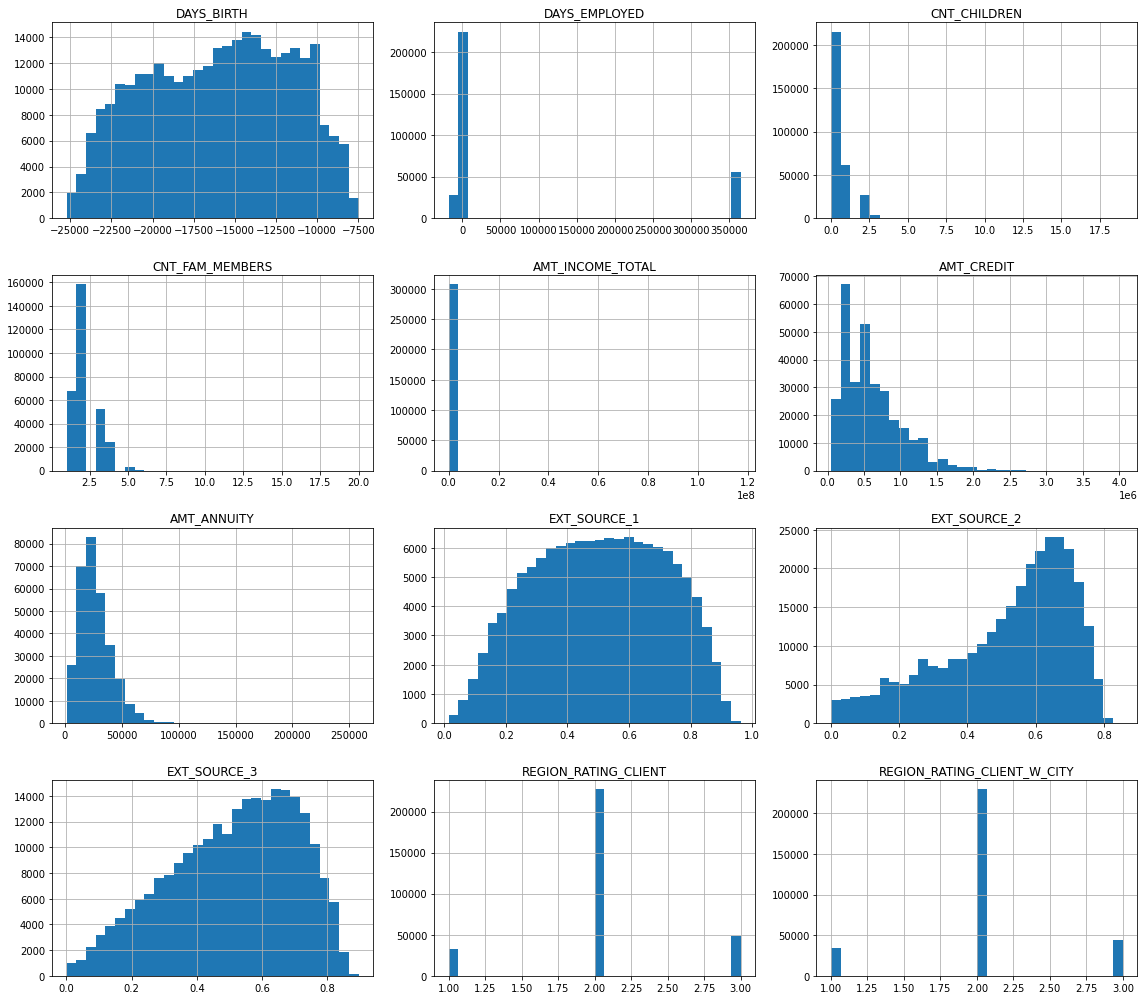

In [9]:
numerical_features = [
    # Applicant demographics
    "DAYS_BIRTH",                  # Age
    "DAYS_EMPLOYED",               # Employment duration
    "CNT_CHILDREN",                # Number of children
    "CNT_FAM_MEMBERS",             # Family size

    # Financial situation
    "AMT_INCOME_TOTAL",            # Annual income
    "AMT_CREDIT",                  # Loan amount
    "AMT_ANNUITY",                 # Loan payment amount

    # External credit scores
    "EXT_SOURCE_1",
    "EXT_SOURCE_2",
    "EXT_SOURCE_3",

    # Regional and social indicators
    "REGION_RATING_CLIENT",
    "REGION_RATING_CLIENT_W_CITY"

]

application_train[numerical_features].hist(
    figsize=(16, 14),
    bins=30
)

plt.tight_layout()
plt.show()

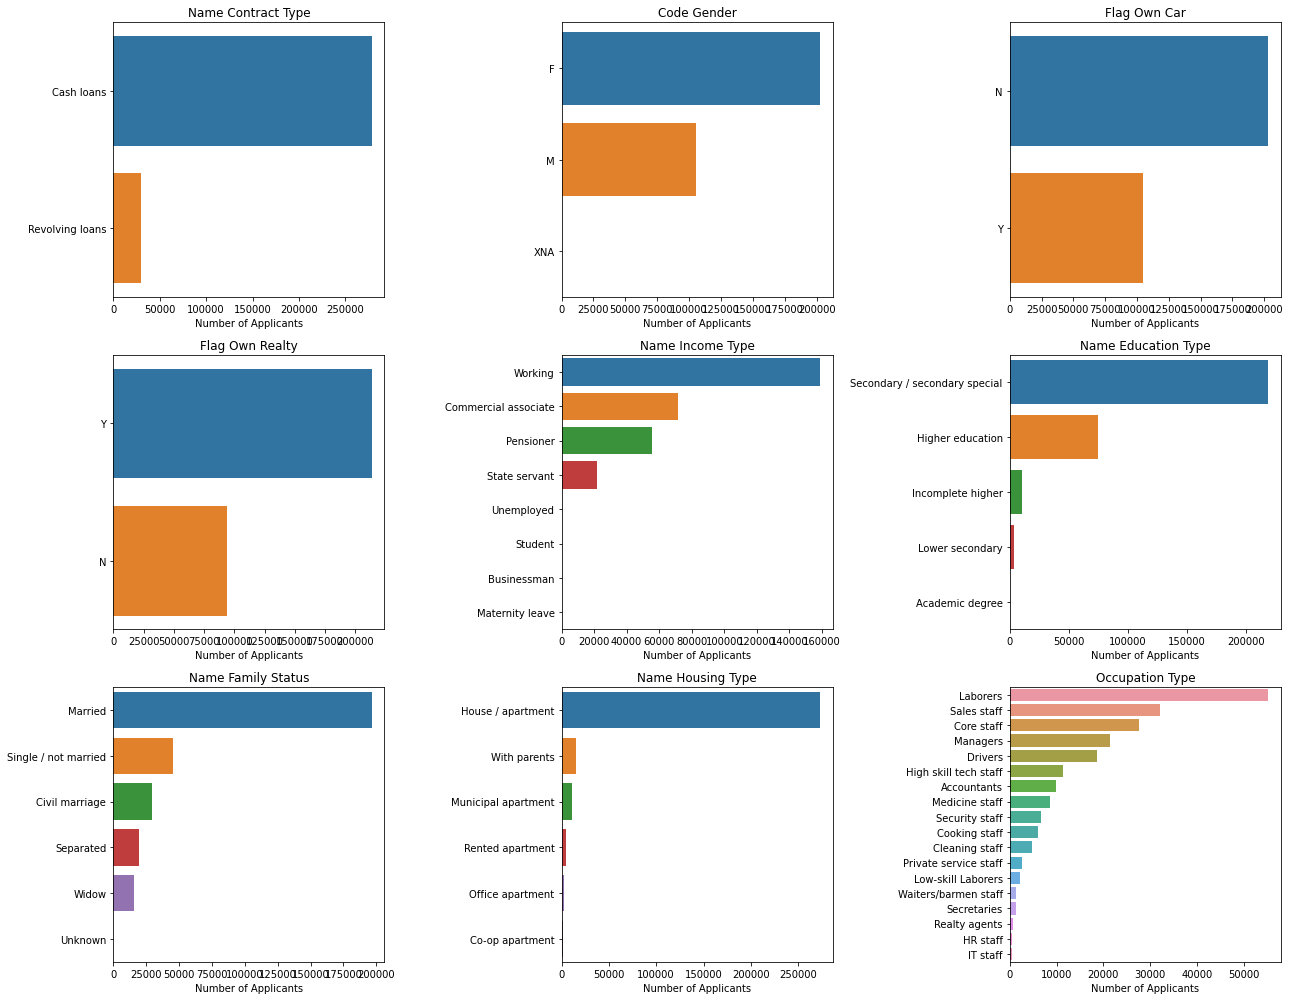

In [10]:
categorical_features = [
    "NAME_CONTRACT_TYPE",   # Loan type
    "CODE_GENDER",          # Gender
    "FLAG_OWN_CAR",         # Car ownership
    "FLAG_OWN_REALTY",      # Property ownership
    "NAME_INCOME_TYPE",     # Income source
    "NAME_EDUCATION_TYPE",  # Education level
    "NAME_FAMILY_STATUS",   # Family status
    "NAME_HOUSING_TYPE",    # Housing situation
    "OCCUPATION_TYPE"       # Occupation
]

# Create bar charts
fig, axes = plt.subplots(3, 3, figsize=(18, 14))

for ax, col in zip(axes.flatten(), categorical_features):
    order = application_train[col].value_counts().index

    sns.countplot(
        data=application_train,
        y=col,
        order=order,
        ax=ax
    )

    ax.set_title(col.replace("_", " ").title())
    ax.set_xlabel("Number of Applicants")
    ax.set_ylabel("")

plt.tight_layout()
plt.show()

## Target Correlation

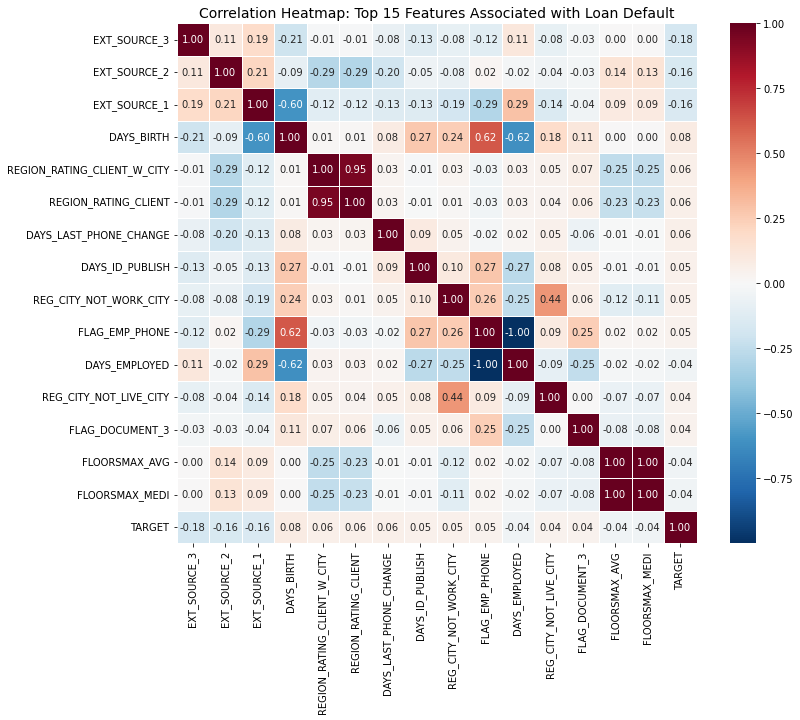

,Correlation with TARGET
DAYS_BIRTH,0.078239
REGION_RATING_CLIENT_W_CITY,0.060893
REGION_RATING_CLIENT,0.058899
DAYS_LAST_PHONE_CHANGE,0.055218
DAYS_ID_PUBLISH,0.051457
REG_CITY_NOT_WORK_CITY,0.050994
FLAG_EMP_PHONE,0.045982
REG_CITY_NOT_LIVE_CITY,0.044395
FLAG_DOCUMENT_3,0.044346
DAYS_REGISTRATION,0.041975


In [11]:
# Select numerical columns only
numeric_data = application_train.select_dtypes(include=["int64", "float64"])

# Calculate correlations with TARGET
correlations = numeric_data.corr()["TARGET"]

# Select 15 features with strongest absolute correlations
top_features = correlations.drop("TARGET").abs().nlargest(15).index

# Create correlation matrix
corr_matrix = numeric_data[list(top_features) + ["TARGET"]].corr()

# Plot heatmap
plt.figure(figsize=(12, 10))

sns.heatmap(
    corr_matrix,
    annot=True,
    cmap="RdBu_r",
    center=0,
    fmt=".2f",
    linewidths=0.5,
    square=True
)

plt.title(
    "Correlation Heatmap: Top 15 Features Associated with Loan Default",
    fontsize=14
)

plt.tight_layout()
plt.show()


# Sort correlations from highest to lowest
correlation_ranking = correlations.drop("TARGET").sort_values(
    ascending=False
)

display(correlation_ranking.to_frame(name="Correlation with TARGET"))

## Target Comparison

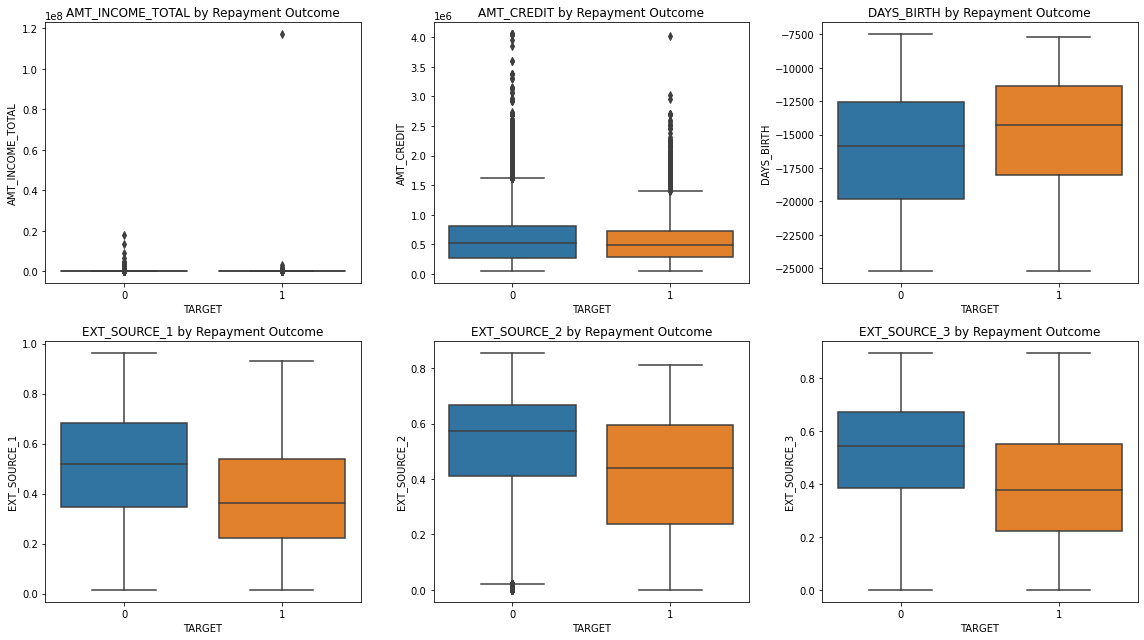

In [12]:
# Compare numerical features by TARGET
features_to_compare = [
    "AMT_INCOME_TOTAL",
    "AMT_CREDIT",
    "DAYS_BIRTH",
    "EXT_SOURCE_1",
    "EXT_SOURCE_2",
    "EXT_SOURCE_3"
]

fig, axes = plt.subplots(2, 3, figsize=(16, 9))

for ax, col in zip(axes.flatten(), features_to_compare):
    sns.boxplot(
        data=application_train,
        x="TARGET",
        y=col,
        ax=ax
    )
    ax.set_title(f"{col} by Repayment Outcome")

plt.tight_layout()
plt.show()

## Age

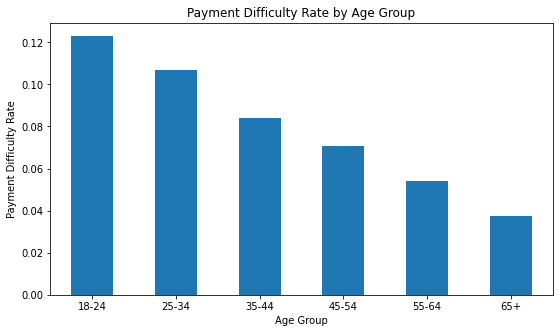

In [13]:
# Convert age from negative days to years
application_train["AGE_YEARS"] = (
    -application_train["DAYS_BIRTH"] / 365
)

# Create age groups
application_train["AGE_GROUP"] = pd.cut(
    application_train["AGE_YEARS"],
    bins=[18, 25, 35, 45, 55, 65, 100],
    labels=["18-24", "25-34", "35-44", "45-54", "55-64", "65+"]
)

# Calculate payment difficulty rate
age_default_rate = application_train.groupby(
    "AGE_GROUP", observed=False
)["TARGET"].mean()

# Visualize
age_default_rate.plot(kind="bar", figsize=(9, 5))

plt.title("Payment Difficulty Rate by Age Group")
plt.xlabel("Age Group")
plt.ylabel("Payment Difficulty Rate")
plt.xticks(rotation=0)
plt.show()

## Affordability

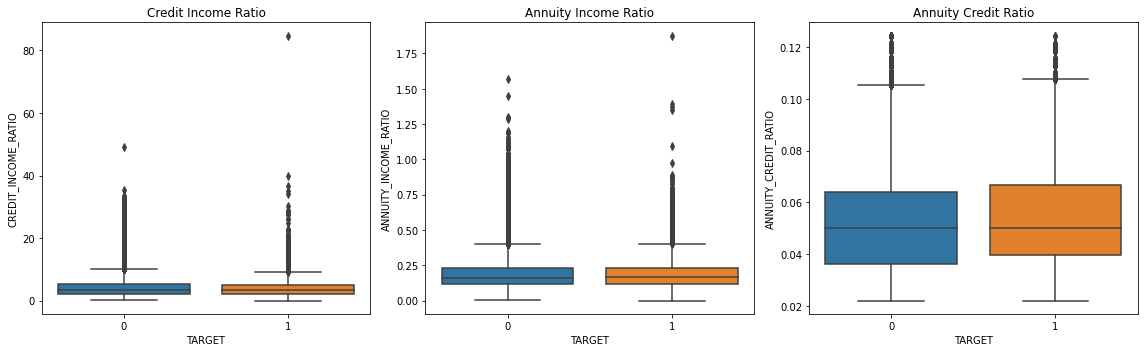

In [14]:
# Create financial ratios
application_train["CREDIT_INCOME_RATIO"] = (
    application_train["AMT_CREDIT"] /
    application_train["AMT_INCOME_TOTAL"].replace(0, np.nan)
)

application_train["ANNUITY_INCOME_RATIO"] = (
    application_train["AMT_ANNUITY"] /
    application_train["AMT_INCOME_TOTAL"].replace(0, np.nan)
)

application_train["ANNUITY_CREDIT_RATIO"] = (
    application_train["AMT_ANNUITY"] /
    application_train["AMT_CREDIT"].replace(0, np.nan)
)

# Compare ratios with TARGET
fig, axes = plt.subplots(1, 3, figsize=(16, 5))

for ax, col in zip(
    axes,
    ["CREDIT_INCOME_RATIO", "ANNUITY_INCOME_RATIO",
     "ANNUITY_CREDIT_RATIO"]
):
    sns.boxplot(data=application_train, x="TARGET", y=col, ax=ax)
    ax.set_title(col.replace("_", " ").title())

plt.tight_layout()
plt.show()

## Default Rates by Categorical Variables

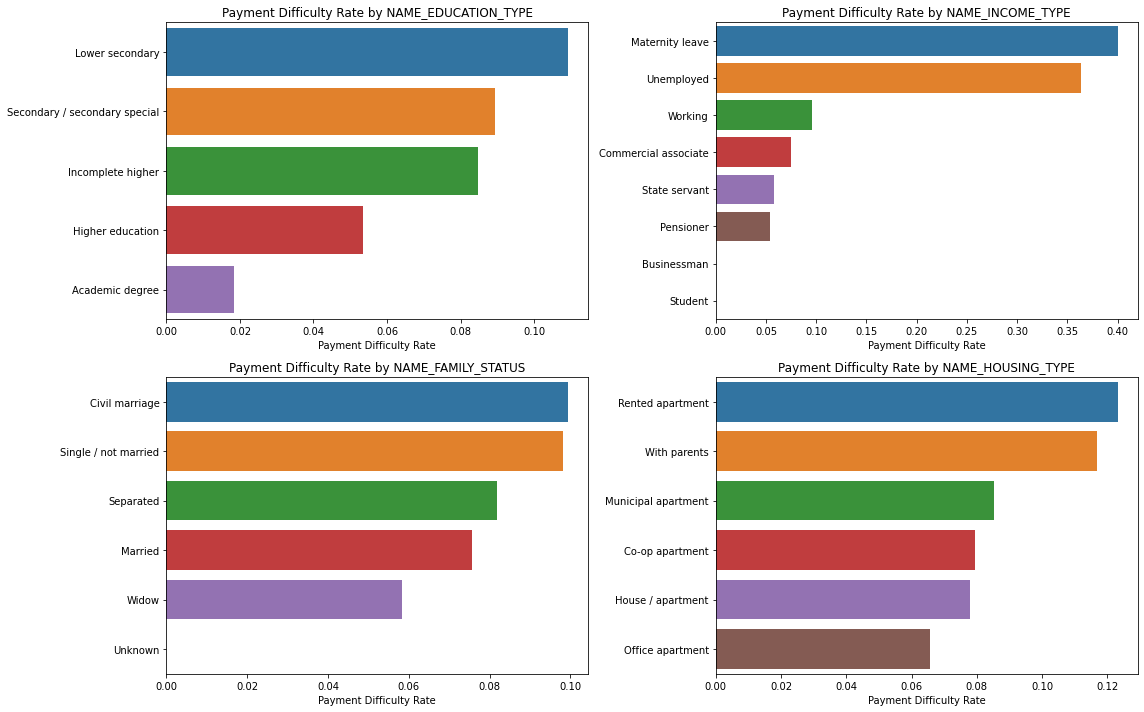

In [15]:
categorical_features = [
    "NAME_EDUCATION_TYPE",
    "NAME_INCOME_TYPE",
    "NAME_FAMILY_STATUS",
    "NAME_HOUSING_TYPE"
]

fig, axes = plt.subplots(2, 2, figsize=(16, 10))

for ax, col in zip(axes.flatten(), categorical_features):

    default_rate = application_train.groupby(col)["TARGET"].mean(
    ).sort_values(ascending=False)

    sns.barplot(
        x=default_rate.values,
        y=default_rate.index,
        ax=ax
    )

    ax.set_title(f"Payment Difficulty Rate by {col}")
    ax.set_xlabel("Payment Difficulty Rate")
    ax.set_ylabel("")

plt.tight_layout()
plt.show()

## EDA: rest of the data

The cells above cover `application_train`. This section is a basic pass over the six history tables: how big they are, what is missing, how many rows each applicant has, and whether having a history relates to default. Each table is read from disk, summarized and dropped before the next one, because holding all of them in memory at once exceeds what the container has.

In [16]:
import gc

# the history tables total several GB, so each one is read, summarized and dropped in turn
history = ["bureau", "bureau_balance", "previous_application",
           "POS_CASH_balance", "credit_card_balance", "installments_payments"]
train_ids = set(application_train["SK_ID_CURR"])
test_ids = set(pd.read_csv(os.path.join(DATA_DIR, "application_test.csv"),
                           usecols=["SK_ID_CURR"])["SK_ID_CURR"])

summary, missing_top, rows_per_applicant = [], {}, {}
for name in history:
    df = pd.read_csv(os.path.join(DATA_DIR, name + ".csv"), encoding="latin1")
    if name == "bureau":
        bureau_map = df.set_index("SK_ID_BUREAU")["SK_ID_CURR"]   # needed to link bureau_balance
    if name == "bureau_balance":
        # no SK_ID_CURR here, so count rows per bureau credit and map them to the applicant
        per_bureau = df.groupby("SK_ID_BUREAU").size()
        per_app = per_bureau.groupby(per_bureau.index.map(bureau_map)).sum()
    else:
        per_app = df.groupby("SK_ID_CURR").size()
    rows_per_applicant[name] = per_app

    miss = df.isna().mean().mul(100).round(1)
    missing_top[name] = miss[miss > 0].sort_values(ascending=False).head(5)
    summary.append({
        "table": name,
        "rows": len(df),
        "columns": df.shape[1],
        "missing_cells_pct": round(df.isna().mean().mean() * 100, 1),
        "applicants": len(per_app),
        "train_coverage_pct": round(per_app.index.isin(train_ids).sum() / len(train_ids) * 100, 1),
        "test_coverage_pct": round(per_app.index.isin(test_ids).sum() / len(test_ids) * 100, 1),
        "rows_per_applicant_mean": round(per_app.mean(), 1),
        "rows_per_applicant_max": per_app.max(),
    })
    del df
    gc.collect()

display(pd.DataFrame(summary).set_index("table"))

,rows,columns,missing_cells_pct,applicants,train_coverage_pct,test_coverage_pct,rows_per_applicant_mean,rows_per_applicant_max
table,,,,,,,,
bureau,1716428,17,13.5,305811,85.7,86.8,5.6,116
bureau_balance,27299925,3,0.0,134542,30.0,86.8,179.7,2791
previous_application,1670214,37,18.0,338857,94.6,98.1,4.9,77
POS_CASH_balance,10001358,8,0.1,337252,94.1,98.1,29.7,295
credit_card_balance,3840312,23,6.7,103558,28.3,34.2,37.1,192
installments_payments,13605401,8,0.0,339587,94.8,98.4,40.1,372


In [17]:
# columns with the most missing values in each history table
for name in history:
    top = missing_top[name]
    print(f"{name}: " + (", ".join(f"{c} ({v}%)" for c, v in top.items()) or "no missing values"))

bureau: AMT_ANNUITY (71.5%), AMT_CREDIT_MAX_OVERDUE (65.5%), DAYS_ENDDATE_FACT (36.9%), AMT_CREDIT_SUM_LIMIT (34.5%), AMT_CREDIT_SUM_DEBT (15.0%)
bureau_balance: no missing values
previous_application: RATE_INTEREST_PRIMARY (99.6%), RATE_INTEREST_PRIVILEGED (99.6%), AMT_DOWN_PAYMENT (53.6%), RATE_DOWN_PAYMENT (53.6%), NAME_TYPE_SUITE (49.1%)
POS_CASH_balance: CNT_INSTALMENT (0.3%), CNT_INSTALMENT_FUTURE (0.3%)
credit_card_balance: AMT_PAYMENT_CURRENT (20.0%), AMT_DRAWINGS_ATM_CURRENT (19.5%), AMT_DRAWINGS_OTHER_CURRENT (19.5%), AMT_DRAWINGS_POS_CURRENT (19.5%), CNT_DRAWINGS_ATM_CURRENT (19.5%)
installments_payments: no missing values


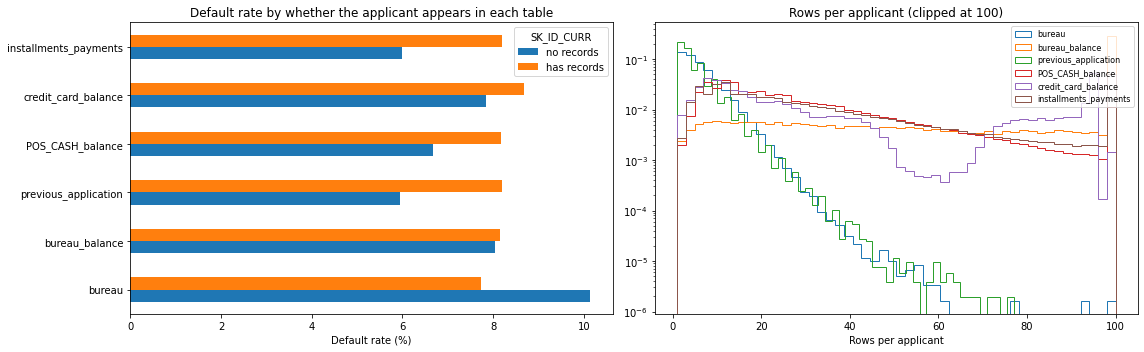

SK_ID_CURR,no records,has records
bureau,10.12,7.73
bureau_balance,8.04,8.14
previous_application,5.96,8.19
POS_CASH_balance,6.66,8.16
credit_card_balance,7.84,8.67
installments_payments,5.98,8.19


In [18]:
# does having a history in a table relate to default? (train applicants only)
train = application_train[["SK_ID_CURR", "TARGET"]]
fig, axes = plt.subplots(1, 2, figsize=(16, 5))

rates = {}
for name in history:
    has = train["SK_ID_CURR"].isin(rows_per_applicant[name].index)
    rates[name] = train.groupby(has)["TARGET"].mean().mul(100)   # index False / True
rates = pd.DataFrame(rates).T.rename(columns={False: "no records", True: "has records"})
rates.plot(kind="barh", ax=axes[0])
axes[0].set_title("Default rate by whether the applicant appears in each table")
axes[0].set_xlabel("Default rate (%)")
axes[0].set_ylabel("")

for name in history:
    axes[1].hist(rows_per_applicant[name].clip(upper=100), bins=50,
                 histtype="step", label=name, density=True)
axes[1].set_yscale("log")
axes[1].set_title("Rows per applicant (clipped at 100)")
axes[1].set_xlabel("Rows per applicant")
axes[1].legend(fontsize=8)

plt.tight_layout()
plt.show()
display(rates.round(2))

Findings from the history tables:

- Coverage varies a lot. `previous_application`, `POS_CASH_balance` and `installments_payments` cover 94 to 95% of training applicants and `bureau` covers 86%. `credit_card_balance` covers 28% and `bureau_balance` 30% (it only has rows for bureau credits that report monthly status). Test coverage is similar to train, so a table being absent is not a train/test quirk.
- Every table has many rows per applicant (mean 5 for `bureau` and `previous_application`, 30 to 40 for the monthly tables, up to 2,791 for `bureau_balance`), so each one has to be aggregated to one row per `SK_ID_CURR` before joining. That is the Phase 3 work.
- Much of the missingness looks structural. The interest-rate columns in `previous_application` are 99.6% empty and `AMT_ANNUITY` in `bureau` is 71.5% empty. Tree models can use this directly. Linear models need imputation plus an indicator.
- Having no history is informative. Applicants with no bureau record default more (10.1% vs 7.7%), and applicants with no previous Home Credit application default less (6.0% vs 8.2%). A record count per table should be a useful feature on its own.

The baselines below use `application_train` only. They don't use these tables, which are saved for the Phase 3 aggregation.

# Define Metrics

Every model outputs a probability $\hat{p}$ that an applicant has payment difficulties. Metrics are computed on held-out rows only and reported as mean ± SD over 5 stratified folds. With about 8% defaults, plain accuracy is misleading (always predicting "no default" scores 92%), so none of the metrics below is accuracy.

### Threshold-free metrics

These use the probabilities directly, so they do not depend on a cutoff.

ROC-AUC is the Kaggle metric and our primary one. With true positive rate and false positive rate computed at every possible cutoff,
$$TPR=\frac{TP}{TP+FN} \qquad FPR=\frac{FP}{FP+TN} \qquad AUC=\int_0^1 TPR\,d(FPR)$$
it equals the probability that a randomly chosen defaulter gets a higher score than a randomly chosen non-defaulter. 0.5 is random ranking and 1.0 is perfect.

Gini rescales AUC so that random is 0 and perfect is 1. Credit scorecards are traditionally reported this way.
$$Gini = 2\cdot AUC - 1$$

KS (Kolmogorov-Smirnov) is the largest gap between the true positive rate and the false positive rate across cutoffs. It measures how far apart the score distributions of defaulters and non-defaulters are at the best cutoff.
$$KS=\max_t\left(TPR_t - FPR_t\right)$$

PR-AUC (average precision) summarizes precision across recall levels, where $R_n$ and $P_n$ are recall and precision at the $n$-th cutoff. A random model scores about the default rate (0.08), so this metric is more sensitive than ROC-AUC when the positive class is rare.
$$AP=\sum_n (R_n - R_{n-1})\,P_n$$

Log loss scores the probabilities themselves and punishes confident wrong predictions heavily. Lower is better. It is the quantity logistic regression minimizes, and it is the one that suffers when we reweight classes, because reweighting inflates the predicted probabilities.
$$\text{LogLoss} = -\frac{1}{N}\sum_{i=1}^{N}\left[y_i \log \hat{p}_i + (1-y_i)\log(1-\hat{p}_i)\right]$$

### Threshold-based metrics

Precision, recall and F1 are computed from hard predictions, so they need a cutoff $t$ (predict default when $\hat{p} \ge t$). Precision is the share of flagged applicants who really default, recall is the share of defaulters we flag, and F1 is their harmonic mean.
$$P=\frac{TP}{TP+FP} \qquad R=\frac{TP}{TP+FN} \qquad F_1=\frac{2PR}{P+R}$$

We report them at the cutoff that maximizes F1 on the pooled out-of-fold predictions. That cutoff is tuned on the same predictions it is scored on, so these three numbers are slightly optimistic. They are there to describe minority-class behavior, not to rank models.

### Evaluation helper

`evaluate` runs the 5 folds for one pipeline. Each fold refits a fresh copy of the whole pipeline on the training part only, so imputers, scalers and encoders never see validation rows. It adds one row to a shared results table and returns the per-fold scores and the out-of-fold probabilities. Using one splitter (`CV`) and one metric dictionary (`SCORING`) keeps every model comparable.

In [ ]:
import time
import numpy as np
import pandas as pd
from sklearn.base import clone
from sklearn.metrics import (average_precision_score, log_loss,
                             precision_recall_curve, roc_auc_score, roc_curve)
from sklearn.model_selection import StratifiedKFold

SEED = 42
# one fixed splitter so every model is scored on identical folds
CV = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)


def gini(y_true, p):
    return 2 * roc_auc_score(y_true, p) - 1


def ks(y_true, p):
    fpr, tpr, _ = roc_curve(y_true, p)
    return (tpr - fpr).max()


# scorer dict: metric name -> f(y_true, predicted probability of default).
# all five are threshold free, so they only need the probabilities
SCORING = {
    "roc_auc": roc_auc_score,
    "pr_auc": average_precision_score,
    "log_loss": log_loss,
    "gini": gini,
    "ks": ks,
}

RESULTS = []   # one row per evaluate() call, shown by results_table()
PIPES, FOLDS, OOF = {}, {}, {}   # by model name: pipeline, per-fold scores, oof probabilities


def evaluate(name, pipe, X, y, cv=CV):
    """cross-validate `pipe`, log one row to RESULTS, return (per-fold table, oof probabilities).

    Each fold refits a fresh clone of the full pipeline on the training part only, so imputers,
    scalers and encoders never see validation rows. Out-of-fold (oof) probabilities are kept to
    choose the F1-optimal threshold for precision / recall / F1.
    """
    oof = np.zeros(len(y))
    folds = []
    for tr, va in cv.split(X, y):
        model = clone(pipe)
        t0 = time.time()
        model.fit(X.iloc[tr], y.iloc[tr])
        fit_s = time.time() - t0

        p_va = model.predict_proba(X.iloc[va])[:, 1]
        p_tr = model.predict_proba(X.iloc[tr])[:, 1]
        oof[va] = p_va
        row = {m: f(y.iloc[va], p_va) for m, f in SCORING.items()}
        row["train_roc_auc"] = roc_auc_score(y.iloc[tr], p_tr)
        row["fit_s"] = fit_s
        folds.append(row)
    folds = pd.DataFrame(folds)

    # threshold that maximises F1 on the pooled oof predictions
    prec, rec, thr = precision_recall_curve(y, oof)
    f1 = 2 * prec * rec / np.clip(prec + rec, 1e-12, None)
    best = f1[:-1].argmax()

    summary = {"model": name}
    for m in SCORING:
        summary[m] = f"{folds[m].mean():.4f} ± {folds[m].std():.4f}"
    summary.update({
        "train_roc_auc": f"{folds['train_roc_auc'].mean():.4f}",
        "threshold": round(thr[best], 3),
        "precision": round(prec[best], 3),
        "recall": round(rec[best], 3),
        "f1": round(f1[best], 3),
        "fit_s": round(folds["fit_s"].mean(), 1),
    })
    RESULTS.append(summary)
    PIPES[name], FOLDS[name], OOF[name] = pipe, folds, oof
    return folds, oof


def results_table():
    return pd.DataFrame(RESULTS).set_index("model")

# Baseline Pipelines

## Scope and leakage controls

The baselines use `application_train` only (307,511 rows, 120 features after dropping `TARGET` and `SK_ID_CURR`). The history tables are aggregated in Phase 3, so this section sets the reference score they need to beat. Models are a dummy classifier that always predicts the training default rate (the ROC-AUC 0.5 floor), logistic regression, a decision tree and a random forest.

To avoid leakage:

- Everything that learns from data (imputer medians, scaler means and variances, one-hot category lists) sits inside a scikit-learn `Pipeline`. Under cross-validation it is refit on the training folds of each split, so validation rows never influence it.
- The cleaning and ratio steps only use values from the same row, so applying them before the split cannot leak.
- `SK_ID_CURR` is dropped and `application_test` is only ever transformed and predicted, never fitted on.
- Hyperparameters are tuned on one 50k subset and the reported cross-validation runs on a different 50k subset, so tuning and scoring share no rows.
- No feature was chosen from the EDA correlations on the full data.

### Block diagram

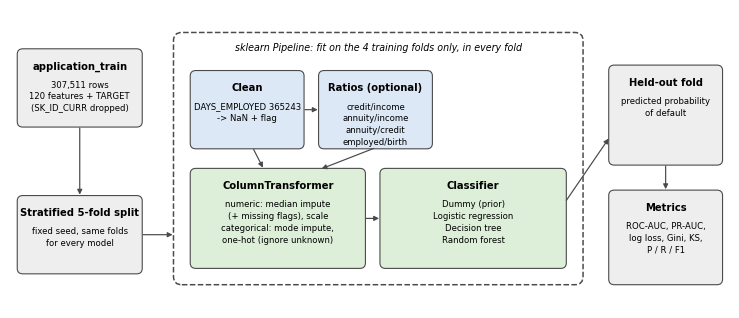

### Data

This is a fresh read of the CSVs, because the EDA cells above added helper columns to `application_train` in place.

In [20]:
import os
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split

# fresh load: the EDA cells above added helper columns to application_train in place
raw = pd.read_csv(os.path.join(DATA_DIR, "application_train.csv"))
test_raw = pd.read_csv(os.path.join(DATA_DIR, "application_test.csv"))

y = raw["TARGET"]
X = raw.drop(columns=["TARGET", "SK_ID_CURR"])   # the id carries no signal
X_test = test_raw.drop(columns=["SK_ID_CURR"])
print(X.shape, X_test.shape, f"default rate {y.mean():.4f}")

(307511, 120) (48744, 120) default rate 0.0807


### Pipeline

`build_pipeline` chains the cleaning step, an optional ratio step, the `ColumnTransformer` and a classifier. Cleaning replaces the `DAYS_EMPLOYED` placeholder (365,243) with NaN and adds a flag column. The ratio step adds credit/income, annuity/income, annuity/credit and days employed/days birth. Numeric columns get median imputation (with missing-value indicator columns) and standard scaling. Categorical columns get most-frequent imputation and one-hot encoding that ignores unseen categories. Scaling does nothing useful for the tree models but is harmless, and it lets all models share one preprocessor.

In [21]:
from sklearn.compose import ColumnTransformer, make_column_selector
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import FunctionTransformer, OneHotEncoder, StandardScaler


def clean(df):
    """replace the DAYS_EMPLOYED placeholder with NaN and flag it. row-wise, so nothing is fitted"""
    df = df.copy()
    placeholder = df["DAYS_EMPLOYED"] == 365243
    df["DAYS_EMPLOYED_ANOM"] = placeholder.astype(int)
    df["DAYS_EMPLOYED"] = df["DAYS_EMPLOYED"].mask(placeholder)
    return df


def add_ratios(df):
    """domain ratios. also row-wise, so applying them before the split cannot leak"""
    df = df.copy()
    income = df["AMT_INCOME_TOTAL"].replace(0, np.nan)
    credit = df["AMT_CREDIT"].replace(0, np.nan)
    df["CREDIT_INCOME_RATIO"] = df["AMT_CREDIT"] / income
    df["ANNUITY_INCOME_RATIO"] = df["AMT_ANNUITY"] / income
    df["ANNUITY_CREDIT_RATIO"] = df["AMT_ANNUITY"] / credit
    df["DAYS_EMPLOYED_RATIO"] = df["DAYS_EMPLOYED"] / df["DAYS_BIRTH"]
    return df


def build_pipeline(model, ratios=False):
    steps = [("clean", FunctionTransformer(clean))]
    if ratios:
        steps.append(("ratios", FunctionTransformer(add_ratios)))
    # imputer medians, scaler means and category lists are learned inside fit(),
    # so under cross-validation they only ever see the training folds
    prep = ColumnTransformer([
        ("num", Pipeline([("impute", SimpleImputer(strategy="median", add_indicator=True)),
                          ("scale", StandardScaler())]),
         make_column_selector(dtype_include="number")),
        ("cat", Pipeline([("impute", SimpleImputer(strategy="most_frequent")),
                          ("onehot", OneHotEncoder(handle_unknown="ignore"))]),
         make_column_selector(dtype_exclude="number")),
    ], sparse_threshold=0)   # dense output, every model below accepts it
    steps += [("prep", prep), ("model", model)]
    return Pipeline(steps)

### Subset choice

Tuning random forests on 307k rows is slow, so we work on stratified subsets of 50k rows (16% of the data). Stratification keeps the default rate at 8.07% in every subset. We take two disjoint ones, one for tuning and one for cross-validation.

To check that 50k rows is enough, the cell below trains on growing samples and scores each on the same held-out 20% of the data. Going from 50k rows to all 246k training rows adds about 0.006 ROC-AUC for logistic regression and about 0.005 for the random forest. At 50k the baselines are close to their full-data score, and the ranking of the models does not change

default rate  full: 0.0807   tuning subset: 0.0807   cv subset: 0.0807


/usr/local/lib/python3.9/site-packages/sklearn/linear_model/_logistic.py:814: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. of ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


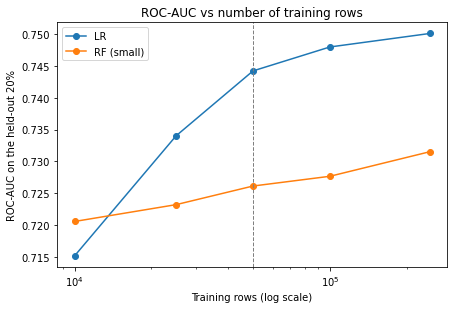

,LR,RF (small)
10000,0.7151,0.7206
25000,0.7340,0.7232
50000,0.7442,0.7261
100000,0.7480,0.7277
246008,0.7501,0.7315


In [22]:
import matplotlib.pyplot as plt
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score

# two disjoint stratified 50k subsets: one to tune hyperparameters, one to cross-validate on,
# so the reported scores never share rows with the tuning
X_dev, X_rest, y_dev, y_rest = train_test_split(X, y, train_size=50_000, stratify=y, random_state=SEED)
X_eval, _, y_eval, _ = train_test_split(X_rest, y_rest, train_size=50_000, stratify=y_rest, random_state=SEED)
print(f"default rate  full: {y.mean():.4f}   tuning subset: {y_dev.mean():.4f}   cv subset: {y_eval.mean():.4f}")

# does a subset of this size give the same answer as all rows? train on growing samples and
# score each one on the same held-out 20% of the data
X_pool, X_hold, y_pool, y_hold = train_test_split(X, y, test_size=0.2, stratify=y, random_state=SEED)
probe = {
    "LR": build_pipeline(LogisticRegression(max_iter=1000, class_weight="balanced")),
    "RF (small)": build_pipeline(RandomForestClassifier(n_estimators=100, max_depth=10, min_samples_leaf=50,
                                                        class_weight="balanced_subsample", n_jobs=-1, random_state=SEED)),
}
sizes = [10_000, 25_000, 50_000, 100_000, len(X_pool)]
curve = {name: [] for name in probe}
for n in sizes:
    if n < len(X_pool):
        Xs, _, ys, _ = train_test_split(X_pool, y_pool, train_size=n, stratify=y_pool, random_state=SEED)
    else:
        Xs, ys = X_pool, y_pool
    for name, pipe in probe.items():
        curve[name].append(roc_auc_score(y_hold, clone(pipe).fit(Xs, ys).predict_proba(X_hold)[:, 1]))

fig, ax = plt.subplots(figsize=(7, 4.5))
for name, vals in curve.items():
    ax.plot(sizes, vals, marker="o", label=name)
ax.axvline(50_000, color="grey", ls="--", lw=1)
ax.set_xscale("log")
ax.set_xlabel("Training rows (log scale)")
ax.set_ylabel("ROC-AUC on the held-out 20%")
ax.set_title("ROC-AUC vs number of training rows")
ax.legend()
plt.show()
display(pd.DataFrame(curve, index=sizes).round(4))

### Hyperparameter tuning

`RandomizedSearchCV` runs 6 random candidates per model on the tuning subset with 3 inner folds, scored by ROC-AUC. It searches `C` for logistic regression, depth and leaf size for the tree, and depth, leaf size and `max_features` for the forest (100 trees). Randomized search covers the same ground as a grid for far fewer fits. Decision tree and forest use class weighting because they otherwise ignore the 8% class.

In [23]:
from scipy.stats import loguniform, randint
from sklearn.model_selection import RandomizedSearchCV, StratifiedKFold
from sklearn.tree import DecisionTreeClassifier

# hyperparameters are tuned on the 50k tuning subset only, with a 3-fold inner split
inner_cv = StratifiedKFold(n_splits=3, shuffle=True, random_state=SEED + 1)

searches = {
    "LR": (LogisticRegression(max_iter=1000, class_weight="balanced"),
           {"model__C": loguniform(1e-3, 1e1)}),
    "DT": (DecisionTreeClassifier(class_weight="balanced", random_state=SEED),
           {"model__max_depth": randint(3, 13), "model__min_samples_leaf": randint(20, 500)}),
    "RF": (RandomForestClassifier(n_estimators=100, class_weight="balanced_subsample",
                                  n_jobs=-1, random_state=SEED),
           {"model__max_depth": randint(6, 21), "model__min_samples_leaf": randint(10, 200),
            "model__max_features": ["sqrt", 0.3]}),
}

best = {}
for name, (est, space) in searches.items():
    search = RandomizedSearchCV(build_pipeline(est), space, n_iter=6, scoring="roc_auc",
                                cv=inner_cv, random_state=SEED, refit=False)
    search.fit(X_dev, y_dev)
    best[name] = {k.removeprefix("model__"): v for k, v in search.best_params_.items()}
    print(f"{name}: inner-cv ROC-AUC {search.best_score_:.4f}  {best[name]}")

/usr/local/lib/python3.9/site-packages/sklearn/linear_model/_logistic.py:814: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. of ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(
/usr/local/lib/python3.9/site-packages/sklearn/linear_model/_logistic.py:814: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. of ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _che

LR: inner-cv ROC-AUC 0.7404  {'C': 0.004207988669606634}
DT: inner-cv ROC-AUC 0.7082  {'max_depth': 9, 'min_samples_leaf': 350}
RF: inner-cv ROC-AUC 0.7391  {'max_depth': 12, 'max_features': 0.3, 'min_samples_leaf': 102}


### Results

Each model is scored with 5-fold stratified cross-validation on the second 50k subset. The table shows mean ± SD over folds

What the table shows:

- Logistic regression and the random forest are within about 0.01 ROC-AUC of each other, and the single decision tree is clearly worse (about 0.705).
- The random forest overfits: about 0.83 ROC-AUC on its training folds against 0.74 on validation folds.
- The four ratio features add about 0.001 to 0.002 ROC-AUC. That is well inside the fold-to-fold SD (about 0.005), so we cannot claim a real improvement from them yet.

In [28]:
from sklearn.dummy import DummyClassifier

# final comparison: 5-fold CV on the 50k cv subset, which shares no rows with the tuning subset.
# scores come from 50k training rows, so a model that keeps improving with data (LR, see the
# curve above) will score a little higher once it is refit on all rows for the submission
lr = lambda **kw: LogisticRegression(max_iter=1000, C=best["LR"]["C"], **kw)
dt = lambda: DecisionTreeClassifier(class_weight="balanced", random_state=SEED, **best["DT"])
rf = lambda: RandomForestClassifier(n_estimators=100, class_weight="balanced_subsample",
                                    n_jobs=-1, random_state=SEED, **best["RF"])

evaluate("Dummy (prior)", build_pipeline(DummyClassifier(strategy="prior")), X_eval, y_eval)
evaluate("LR", build_pipeline(lr()), X_eval, y_eval)
evaluate("LR balanced", build_pipeline(lr(class_weight="balanced")), X_eval, y_eval)
evaluate("DT", build_pipeline(dt()), X_eval, y_eval)
evaluate("RF", build_pipeline(rf()), X_eval, y_eval)

# same models with the four ratio features, to measure what they add
evaluate("LR balanced + ratios", build_pipeline(lr(class_weight="balanced"), ratios=True), X_eval, y_eval)
evaluate("RF + ratios", build_pipeline(rf(), ratios=True), X_eval, y_eval)

display(results_table())

,roc_auc,pr_auc,log_loss,gini,ks,train_roc_auc,threshold,precision,recall,f1,fit_s
model,,,,,,,,,,,
Dummy (prior),0.5000 ± 0.0000,0.0807 ± 0.0001,0.2806 ± 0.0001,0.0000 ± 0.0000,0.0000 ± 0.0000,0.5000,0.081,0.081,1.000,0.149,2.0
LR,0.7462 ± 0.0053,0.2241 ± 0.0082,0.2501 ± 0.0014,0.4924 ± 0.0106,0.3729 ± 0.0066,0.7556,0.140,0.224,0.424,0.293,4.3
LR balanced,0.7464 ± 0.0053,0.2232 ± 0.0083,0.5898 ± 0.0053,0.4928 ± 0.0106,0.3734 ± 0.0078,0.7588,0.644,0.220,0.433,0.292,6.9
DT,0.7047 ± 0.0060,0.1820 ± 0.0042,0.6223 ± 0.0130,0.4095 ± 0.0121,0.3176 ± 0.0127,0.7511,0.660,0.200,0.384,0.263,4.2
RF,0.7411 ± 0.0063,0.2194 ± 0.0030,0.5268 ± 0.0045,0.4822 ± 0.0127,0.3624 ± 0.0102,0.8313,0.588,0.219,0.415,0.287,14.4
LR balanced + ratios,0.7478 ± 0.0053,0.2234 ± 0.0078,0.5890 ± 0.0046,0.4957 ± 0.0106,0.3761 ± 0.0082,0.7604,0.663,0.230,0.402,0.293,7.3
RF + ratios,0.7424 ± 0.0048,0.2209 ± 0.0047,0.5230 ± 0.0037,0.4849 ± 0.0097,0.3699 ± 0.0029,0.8361,0.599,0.231,0.384,0.289,13.5


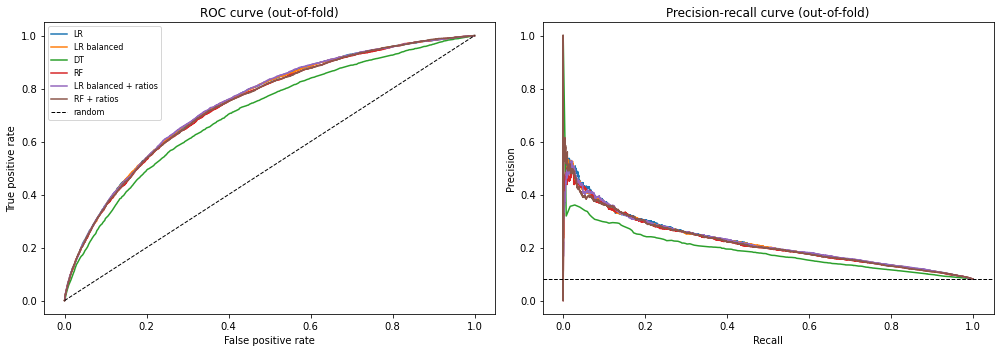

In [29]:
from sklearn.metrics import precision_recall_curve, roc_curve

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for name, oof in OOF.items():
    if name.startswith("Dummy"):
        continue
    fpr, tpr, _ = roc_curve(y_eval, oof)
    prec, rec, _ = precision_recall_curve(y_eval, oof)
    axes[0].plot(fpr, tpr, label=name)
    axes[1].plot(rec, prec, label=name)
axes[0].plot([0, 1], [0, 1], "k--", lw=1, label="random")
axes[0].set(title="ROC curve (out-of-fold)", xlabel="False positive rate", ylabel="True positive rate")
axes[1].axhline(y_eval.mean(), color="k", ls="--", lw=1, label="random (default rate)")
axes[1].set(title="Precision-recall curve (out-of-fold)", xlabel="Recall", ylabel="Precision")
axes[0].legend(fontsize=8)
plt.tight_layout()
plt.show()

### Kaggle submission

The best pipeline by mean CV ROC-AUC is refit once on all training rows and used to predict `application_test`. The file is saved in `data/` (git ignored) and can be uploaded on the Kaggle competition page as a late submission

In [30]:
# refit the best pipeline (by mean CV ROC-AUC) once on all training rows and predict the test set
best_name = max((n for n in FOLDS if not n.startswith("Dummy")), key=lambda n: FOLDS[n]["roc_auc"].mean())
print("best model:", best_name)

final = clone(PIPES[best_name]).fit(X, y)
submission = pd.DataFrame({
    "SK_ID_CURR": test_raw["SK_ID_CURR"],
    "TARGET": final.predict_proba(X_test)[:, 1],
})
out = os.path.join(DATA_DIR, "submission_phase2.csv")   # data/ is git ignored
submission.to_csv(out, index=False)
print(out, submission.shape, "| mean predicted probability:", submission["TARGET"].mean().round(4))

best model: LR balanced + ratios
/root/shared/group1-hcdr-no-cap/data/submission_phase2.csv (48744, 2) | mean predicted probability: 0.4171


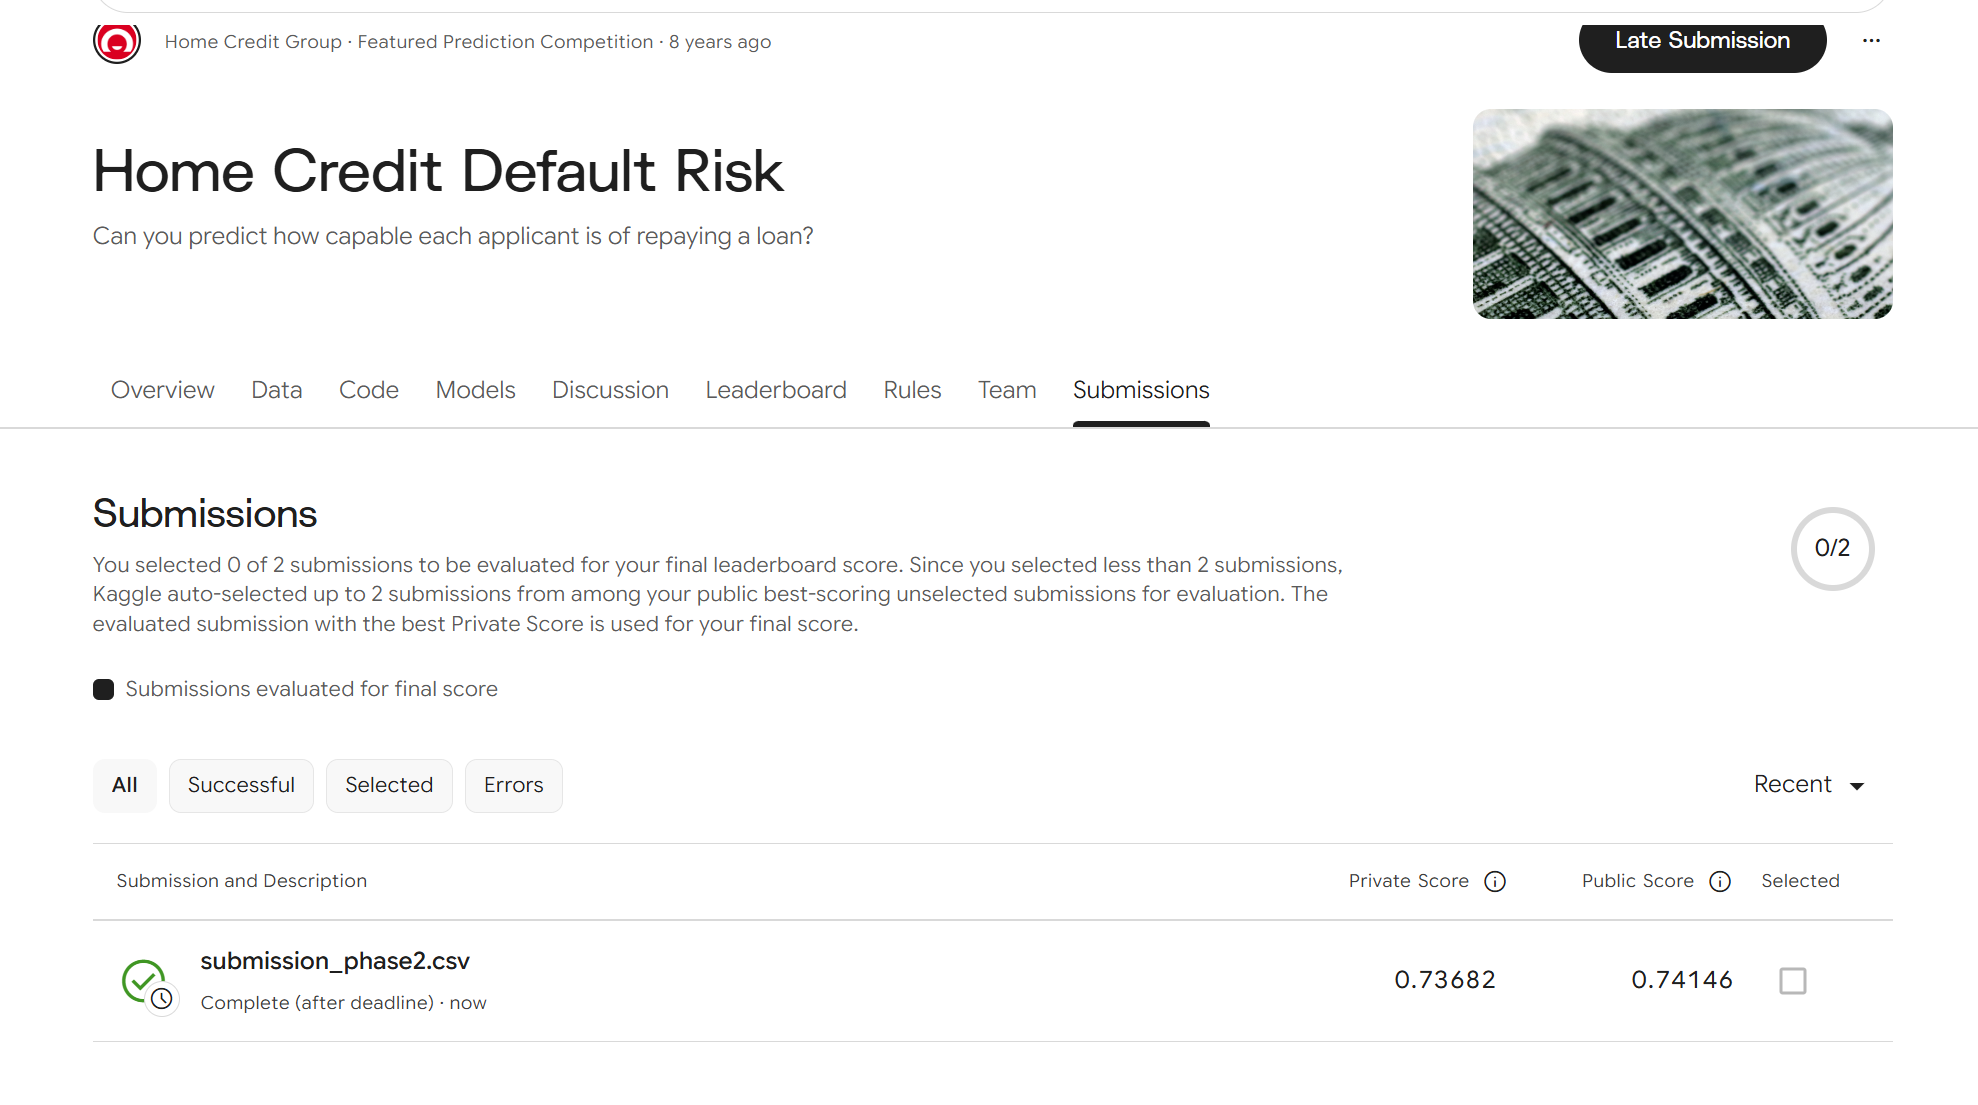

# Report

### What we did

We built the Phase 2 baseline on the application table alone and checked it against the Kaggle leaderboard. The best pipeline, logistic regression with class weights and four ratio features, reaches a cross-validated ROC-AUC of 0.748. Refit on all training rows, the same pipeline scores 0.737 on the private leaderboard and 0.741 on the public one.

The EDA covers all eight tables. The history tables have many rows per applicant (a mean of about 5 for `bureau` and `previous_application`, 30 to 40 for the monthly tables), so they need aggregation before they can be joined. Having no history is itself informative: applicants with no bureau record default more (10.1% against 7.7%), and applicants with no previous Home Credit application default less (6.0% against 8.2%).

The baselines use `application_train` only. Cleaning, optional ratio features, imputation, scaling and one-hot encoding sit in one scikit-learn `Pipeline` that is refit inside every cross-validation fold, so no fitted step sees validation rows. We compared a dummy classifier, logistic regression, a decision tree and a random forest. Hyperparameters came from a randomized search on one stratified 50k-row subset, and the scores below come from 5-fold cross-validation on a second, disjoint 50k subset. Training on 246k rows instead of 50k raised held-out ROC-AUC by only about 0.006 for logistic regression and 0.005 for the random forest, so we think the subset is enough for a baseline.

### Results

Cross-validated scores, mean ± SD over 5 folds:

| model | ROC-AUC | PR-AUC | log loss | train ROC-AUC |
|:---|:---:|:---:|:---:|:---:|
| dummy (prior) | 0.5000 ± 0.0000 | 0.0807 | 0.2806 | 0.5000 |
| logistic regression | 0.7462 ± 0.0053 | 0.2241 | 0.2501 | 0.7556 |
| logistic regression, balanced | 0.7464 ± 0.0053 | 0.2232 | 0.5898 | 0.7588 |
| decision tree | 0.7047 ± 0.0060 | 0.1820 | 0.6223 | 0.7511 |
| random forest | 0.7411 ± 0.0063 | 0.2194 | 0.5268 | 0.8313 |
| logistic regression, balanced, + ratios | 0.7478 ± 0.0053 | 0.2234 | 0.5890 | 0.7604 |
| random forest + ratios | 0.7424 ± 0.0048 | 0.2209 | 0.5230 | 0.8361 |

### What the results say

Logistic regression and the random forest are close, and the single decision tree is clearly behind. The forest overfits, 0.83 ROC-AUC on its training folds and 0.74 on validation folds. The tree overfits less in absolute terms (0.75 against 0.70) but is a weaker model. Class weighting leaves ROC-AUC unchanged and more than doubles log loss, because it inflates the predicted probabilities, so those outputs would need recalibrating before anyone read them as default probabilities. The ratio features add 0.001 to 0.002 ROC-AUC, which is inside the fold-to-fold SD of about 0.005, so we cannot say they help

The leaderboard scores are lower than the cross-validation score by 0.006 (public) and 0.011 (private). Logistic regression trained on 246k rows scored 0.750 on held-out training rows, and the same kind of model scores 0.737 to 0.741 on the Kaggle test set. Either the test set differs somewhat from the training data, or the leaderboard subsets are small enough to be noisy

![Team](team.png)